<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">📘 Batch, micro-batch a streaming - Northwind </h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">V nadväznosti na Seminár 8 - Zadanie 1a s MovieLens spracujeme údaje o objednávkach. Tentoraz si jednotlivé kroky naprogramujete samostatne od načítania CSV po porovnanie výsledkov.</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z kurzu si stiahnite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> (stĺpce <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">customerid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">employeeid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid</code>). Súbor uložte do rovnakého priečinka ako notebook. Knižnice a PostgreSQL už máte pripravené.</p>

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 1 – Načítanie a časová distribúcia objednávok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Načítajte súbor <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> a zmeňte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> na dátum. Zistite časový rozsah a počet objednávok podľa roku a mesiaca. Rozloženie zobrazte v grafe.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">pd.read_csv(..., parse_dates=["orderdate"])</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.year</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.to_period("M")</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">value_counts()</code>.</div>

Počet objednávok: 196
Časový rozsah: 1996-07-04 – 1997-02-12

Objednávky podľa roku:
orderdate
1996    152
1997     44

Objednávky podľa mesiaca:
orderdate
1996-07    22
1996-08    25
1996-09    23
1996-10    26
1996-11    25
1996-12    31
1997-01    33
1997-02    11
Freq: M


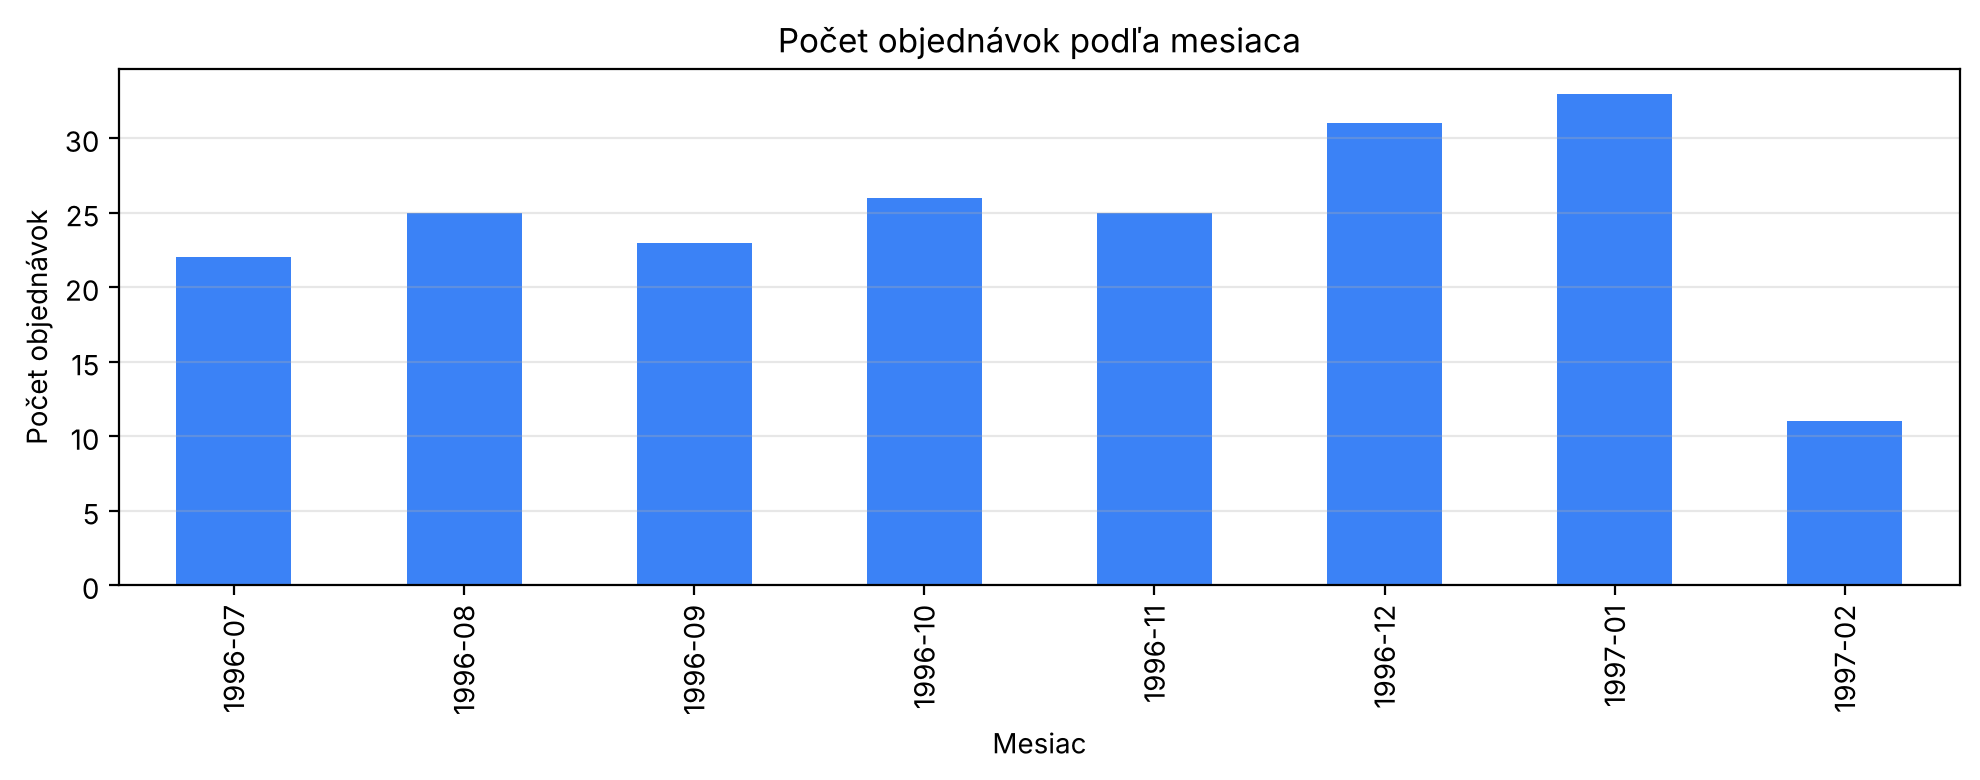

In [1]:
import time

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

orders = pd.read_csv("orders.csv", parse_dates=["orderdate"])

print("Počet objednávok:", len(orders))
print("Časový rozsah:", orders["orderdate"].min().date(), "–", orders["orderdate"].max().date())

by_year = orders["orderdate"].dt.year.value_counts().sort_index()
by_month = orders["orderdate"].dt.to_period("M").value_counts().sort_index()

print("\nObjednávky podľa roku:")
print(by_year.to_string())
print("\nObjednávky podľa mesiaca:")
print(by_month.to_string())

ax = by_month.plot(kind="bar", figsize=(10, 4), color="#3b82f6")
ax.set_title("Počet objednávok podľa mesiaca")
ax.set_xlabel("Mesiac")
ax.set_ylabel("Počet objednávok")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 2 – Historické a novšie objednávky</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Podľa časového rozloženia zvoľte <strong>hranice 1. januára 1997</strong>. Staršie objednávky budú historický batch, objednávky od tohto dátumu využijeme na simuláciu príchodu udalostí.</p>
<ul style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.7; margin-top: 6px; padding-left: 24px;"><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">historical_orders</code> budú objednávky pred hranicou,</li><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">new_orders</code> naopak objednávky od hranice (vrátane),</li><li style="margin-bottom: 5px;">overte, že obe skupiny spolu obsahujú všetky objednávky.</li></ul>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong>Upozornenie: </strong> „Novšie“ objednávky sú stále <strong>historické záznamy</strong>. V nasledujúcich úlohách budeme ich príchod len simulovať.</div>

In [2]:
CUTOFF = pd.Timestamp("1997-01-01")

historical_orders = orders[orders["orderdate"] < CUTOFF].copy()
new_orders = orders[orders["orderdate"] >= CUTOFF].copy()

print("Historické objednávky:", len(historical_orders))
print("Novšie objednávky:", len(new_orders))

assert len(historical_orders) + len(new_orders) == len(orders), "Niektoré objednávky chýbajú"

Historické objednávky: 152
Novšie objednávky: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 3 – Raw ingestion do PostgreSQL</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte databázu <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">Northwind</code>, tabuľku <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> s primárnym kľúčom <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code> a nahrajte všetky záznamy z CSV. Predpokladáme, že PostgreSQL a balíky už fungujú inštaláciu ani test verzie preto nemusíte riešiť.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> najskôr sa pripojte do databázy <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">postgres</code>, vytvorte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders_practice</code> s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">AUTOCOMMIT</code>, potom zmeňte pripojenie. Na opakovateľný import použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">DROP TABLE IF EXISTS</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">to_sql(..., if_exists="append", index=False)</code>.</div>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong> Upozornenie:</strong> Pri opakovanom spustení sa obsah tabuľky <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> vymaže a znovu nahrá. Nepoužívajte názov databázy, ktorá už obsahuje vaše vlastné dáta.</div>

In [3]:
# Prihlasovacie údaje k lokálnemu PostgreSQL – upravte podľa svojej inštalácie
PG_USER = "postgres"
PG_PASSWORD = "postgres"
PG_HOST = "localhost"
PG_PORT = 5432
DB_NAME = "orders_practice"   # samostatná databáza, aby sa neprepísali iné dáta

BASE_URL = f"postgresql+psycopg2://{PG_USER}:{PG_PASSWORD}@{PG_HOST}:{PG_PORT}"

# 1) Pripojenie do systémovej databázy postgres a vytvorenie cieľovej DB (CREATE DATABASE vyžaduje AUTOCOMMIT)
admin_engine = create_engine(f"{BASE_URL}/postgres", isolation_level="AUTOCOMMIT")
with admin_engine.connect() as conn:
    exists = conn.execute(
        text("SELECT 1 FROM pg_database WHERE datname = :name"), {"name": DB_NAME}
    ).scalar()
    if not exists:
        conn.execute(text(f'CREATE DATABASE "{DB_NAME}"'))
admin_engine.dispose()

# 2) Prepnutie na novú databázu, opakovateľné vytvorenie tabuľky a import
engine = create_engine(f"{BASE_URL}/{DB_NAME}")

with engine.begin() as conn:
    conn.execute(text("DROP TABLE IF EXISTS orders"))
    conn.execute(text("""
        CREATE TABLE orders (
            orderid    INTEGER PRIMARY KEY,
            customerid INTEGER,
            employeeid INTEGER,
            orderdate  TIMESTAMP,
            shipperid  INTEGER
        )
    """))

orders.to_sql("orders", engine, if_exists="append", index=False)

with engine.connect() as conn:
    db_count = conn.execute(text("SELECT COUNT(*) FROM orders")).scalar()

assert db_count == len(orders), f"V DB je {db_count} riadkov, v CSV {len(orders)}"
print("Tabuľka orders bola vytvorená a naplnená.")

Tabuľka orders bola vytvorená a naplnená.


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 4 – Batch processing</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z historických objednávok vypočítajte <strong>počet objednávok</strong>, <strong>počet zákazníkov</strong> a <strong>percento objednávok s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid = 3</code></strong>. Výsledok získame jednorazovo za celú historickú skupinu.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Percento vypočítate ako <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(počet objednávok dopravcu 3 / počet všetkých objednávok) * 100</code>. Výraz <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(df["shipperid"] == 3).sum()</code> spočíta vyhovujúce riadky.</div>

In [4]:
hist_order_count = len(historical_orders)
hist_customer_count = historical_orders["customerid"].nunique()
hist_shipper3_pct = (historical_orders["shipperid"] == 3).sum() / hist_order_count * 100

print("Objednávok:", hist_order_count)
print("Zákazníkov:", hist_customer_count)
print(f"Dopravca 3 (%): {hist_shipper3_pct:.2f}")

Objednávok: 152
Zákazníkov: 66
Dopravca 3 (%): 38.16


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 5 – Spoločná vzorka pre tri prístupy</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na porovnanie musí každý prístup dostať <strong>rovnaké objednávky v rovnakom poradí</strong>. Z PostgreSQL vyberte novšie objednávky a zoraďte ich podľa <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">text()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">engine.connect()</code> a pomenované parametre SQL <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:cutoff</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:limit</code>. V tomto datasete je po hranici 44 objednávok, preto postačuje <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">SAMPLE_SIZE = 44</code>.</div>

In [5]:
SAMPLE_SIZE = 44

sample_query = text("""
    SELECT orderid, customerid, employeeid, orderdate, shipperid
    FROM orders
    WHERE orderdate >= :cutoff
    ORDER BY orderdate, orderid
    LIMIT :limit
""")

with engine.connect() as conn:
    sample = pd.read_sql(
        sample_query, conn,
        params={"cutoff": CUTOFF.to_pydatetime(), "limit": SAMPLE_SIZE},
    )

print("Objednávok v simulácii:", len(sample))

Objednávok v simulácii: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 6 – Simulácia micro-batchingu a streamingu</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Historické objednávky budeme prehrávať postupne. <strong>Streaming</strong> aktualizuje podiel dopravcu 3 po každej objednávke, <strong>micro-batch</strong> po uzavretí krátkeho časového okna. Batch poskytne výsledok až po príchode celej vzorky.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Pre tento malý dataset nastavíme <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">EVENT_DELAY_SEC = 0.04</code> (40 ms medzi objednávkami) a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">MICRO_WINDOW_SEC = 0.30</code> (približne 300 ms na dávku). Skutočné časy závisia od výkonu počítača.</div>

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok A – Nastavenia a priebežný stav</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Pripravte časové parametre, počítadlá a zoznamy na zaznamenávanie priebežných výsledkov. Pri micro-batchingu potrebujeme navyše premenné pre neuzavretú dávku.</p>

In [6]:
EVENT_DELAY_SEC = 0.04    # pauza medzi príchodom dvoch objednávok
MICRO_WINDOW_SEC = 0.30   # dĺžka jedného micro-batch okna
TARGET_SHIPPER = 3

# Streaming – priebežný stav po každej udalosti
running_count = 0         # počet spracovaných objednávok
running_sum = 0           # počet objednávok dopravcu 3
stream_log = []           # (čas, počet, percento)

# Micro-batch – priebežný stav po uzavretí okna
mb_running_count = 0
mb_running_sum = 0
mb_log = []               # (čas, počet, percento)
mb_buffer = []            # objednávky v aktuálne otvorenom okne

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok B – Spracovanie udalostí</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Prejdite objednávky postupne. Pri streamingu priebežne zapisujte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(čas, počet, percento)</code>. Pri micro-batchingu spracujte nazbierané objednávky až po uplynutí okna.</p>

In [7]:
start = time.perf_counter()
window_start = start

for i in range(len(sample)):
    time.sleep(EVENT_DELAY_SEC)            # simulácia príchodu ďalšej objednávky
    order = sample.iloc[i]
    is_target = int(order["shipperid"] == TARGET_SHIPPER)
    now = time.perf_counter()

    # Streaming: výsledok sa aktualizuje hneď po každej objednávke
    running_count += 1
    running_sum += is_target
    stream_log.append((now - start, running_count, running_sum / running_count * 100))

    # Micro-batch: objednávky sa zbierajú a spracujú až po uplynutí okna
    mb_buffer.append(is_target)
    if now - window_start >= MICRO_WINDOW_SEC:
        mb_running_count += len(mb_buffer)
        mb_running_sum += sum(mb_buffer)
        mb_log.append((now - start, mb_running_count, mb_running_sum / mb_running_count * 100))
        mb_buffer = []
        window_start = now

print("Streaming aktualizácií:", len(stream_log))
print("Uzavretých micro-batch okien:", len(mb_log), "| v neuzavretej dávke:", len(mb_buffer))

Streaming aktualizácií: 44
Uzavretých micro-batch okien: 5 | v neuzavretej dávke: 4


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok C – Posledná dávka a batch</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Nezabudnite spracovať poslednú nedokončenú micro-batch dávku. Nakoniec vypočítajte jednorazový batch výsledok pre tú istú vzorku a overte rovnosť výsledných percent.</p>

In [8]:
# Posledná, neúplná micro-batch dávka
if mb_buffer:
    mb_running_count += len(mb_buffer)
    mb_running_sum += sum(mb_buffer)
    mb_log.append((time.perf_counter() - start, mb_running_count,
                   mb_running_sum / mb_running_count * 100))
    mb_buffer = []

# Batch: jeden výpočet až po príchode celej vzorky
batch_pct = (sample["shipperid"] == TARGET_SHIPPER).sum() / len(sample) * 100
batch_log = [(time.perf_counter() - start, len(sample), batch_pct)]

mb_pct = mb_log[-1][2]
stream_pct = stream_log[-1][2]

print("Počet objednávok:", len(sample))
print(f"Batch (%): {batch_pct:.2f}")
print(f"Micro-batch (%): {mb_pct:.2f}")
print(f"Streaming (%): {stream_pct:.2f}")

assert mb_log[-1][1] == stream_log[-1][1] == len(sample)
assert abs(batch_pct - mb_pct) < 1e-9 and abs(batch_pct - stream_pct) < 1e-9

Počet objednávok: 44
Batch (%): 22.73
Micro-batch (%): 22.73
Streaming (%): 22.73


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 7 – Grafy priebežných výsledkov</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte <strong>tri samostatné grafy</strong> pod sebou. V prvom zobrazte jednorazový batch bod, v druhom schodovitý priebeh micro-batchingu a v treťom streamingovú krivku. Použite spoločné osi, aby boli percentá porovnateľné.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plt.subplots(3, 1, sharex=True, sharey=True)</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">scatter()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">step(where="post")</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plot()</code>.</div>

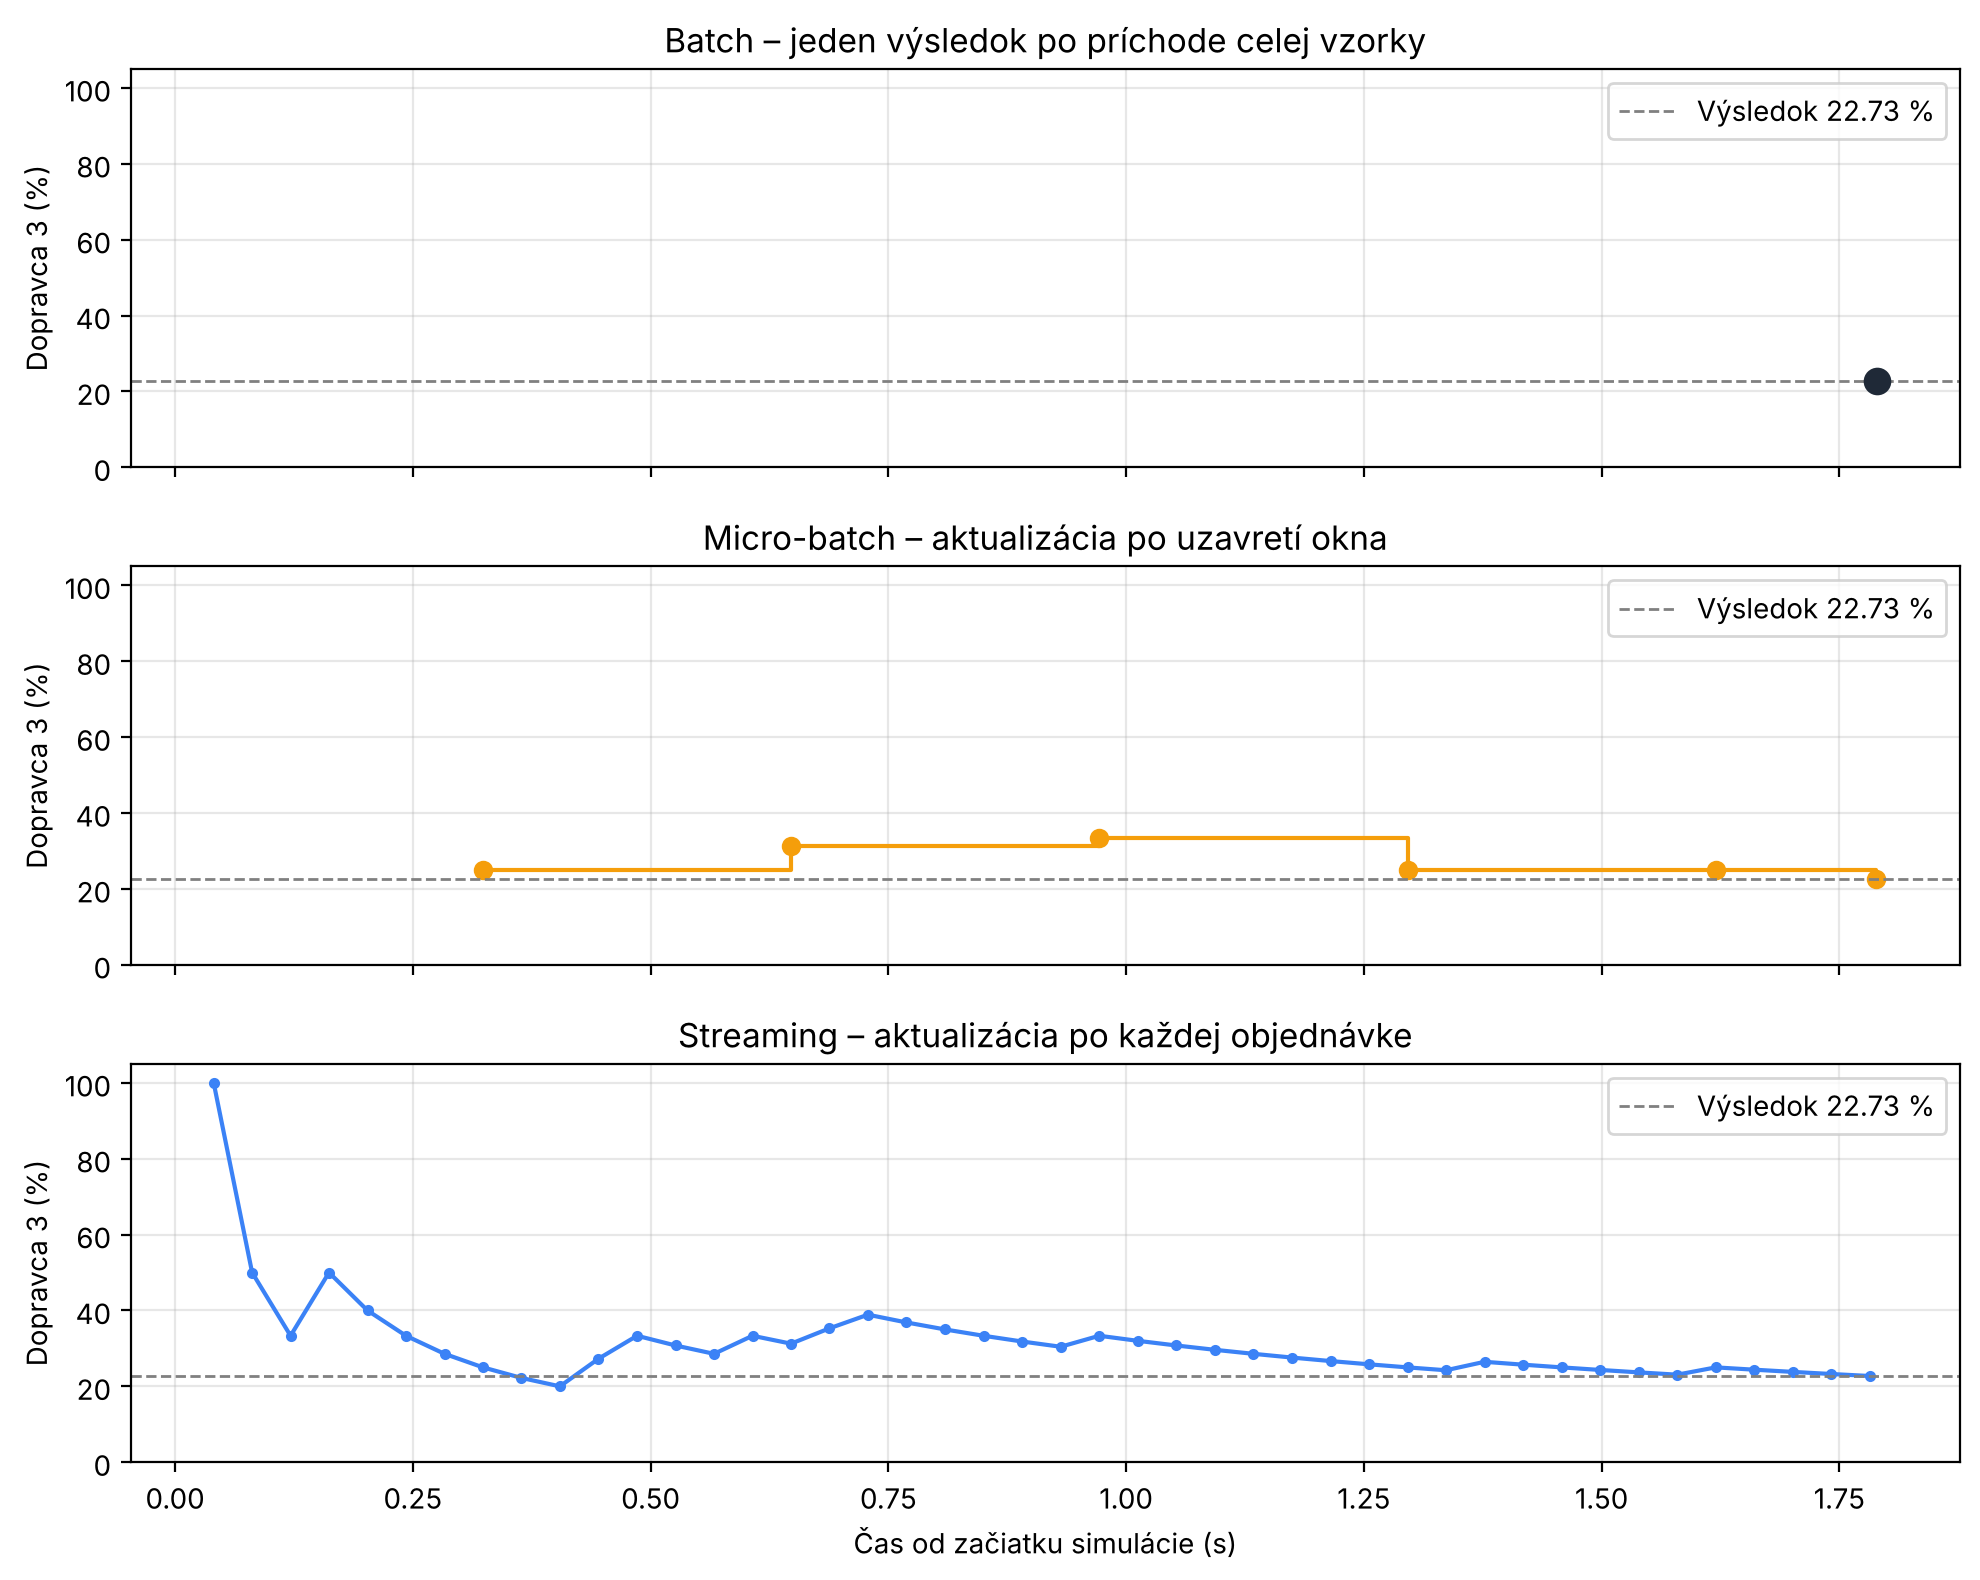

In [9]:
b_t, _, b_p = zip(*batch_log)
m_t, _, m_p = zip(*mb_log)
s_t, _, s_p = zip(*stream_log)

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, sharey=True)

axes[0].scatter(b_t, b_p, s=80, color="#1f2937", zorder=3)
axes[0].set_title("Batch – jeden výsledok po príchode celej vzorky")

axes[1].step(m_t, m_p, where="post", marker="o", color="#f59e0b")
axes[1].set_title("Micro-batch – aktualizácia po uzavretí okna")

axes[2].plot(s_t, s_p, marker=".", color="#3b82f6")
axes[2].set_title("Streaming – aktualizácia po každej objednávke")

for ax in axes:
    ax.axhline(batch_pct, linestyle="--", color="gray", linewidth=1, label=f"Výsledok {batch_pct:.2f} %")
    ax.set_ylabel("Dopravca 3 (%)")
    ax.set_ylim(0, 105)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Čas od začiatku simulácie (s)")
plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 8 – Frekvencia aktualizácií a prvý výsledok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na troch grafoch znázornite, koľkokrát sa priebežný výsledok aktualizoval. Potom vytvorte jednoduchú tabuľku, ktorá porovná <strong>čas prvého výsledku</strong>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Pri počte aktualizácií nie je vhodné zdieľať os Y: batch má jeden výsledok, streaming jeden po každej udalosti. Os X zdieľajte.</div>

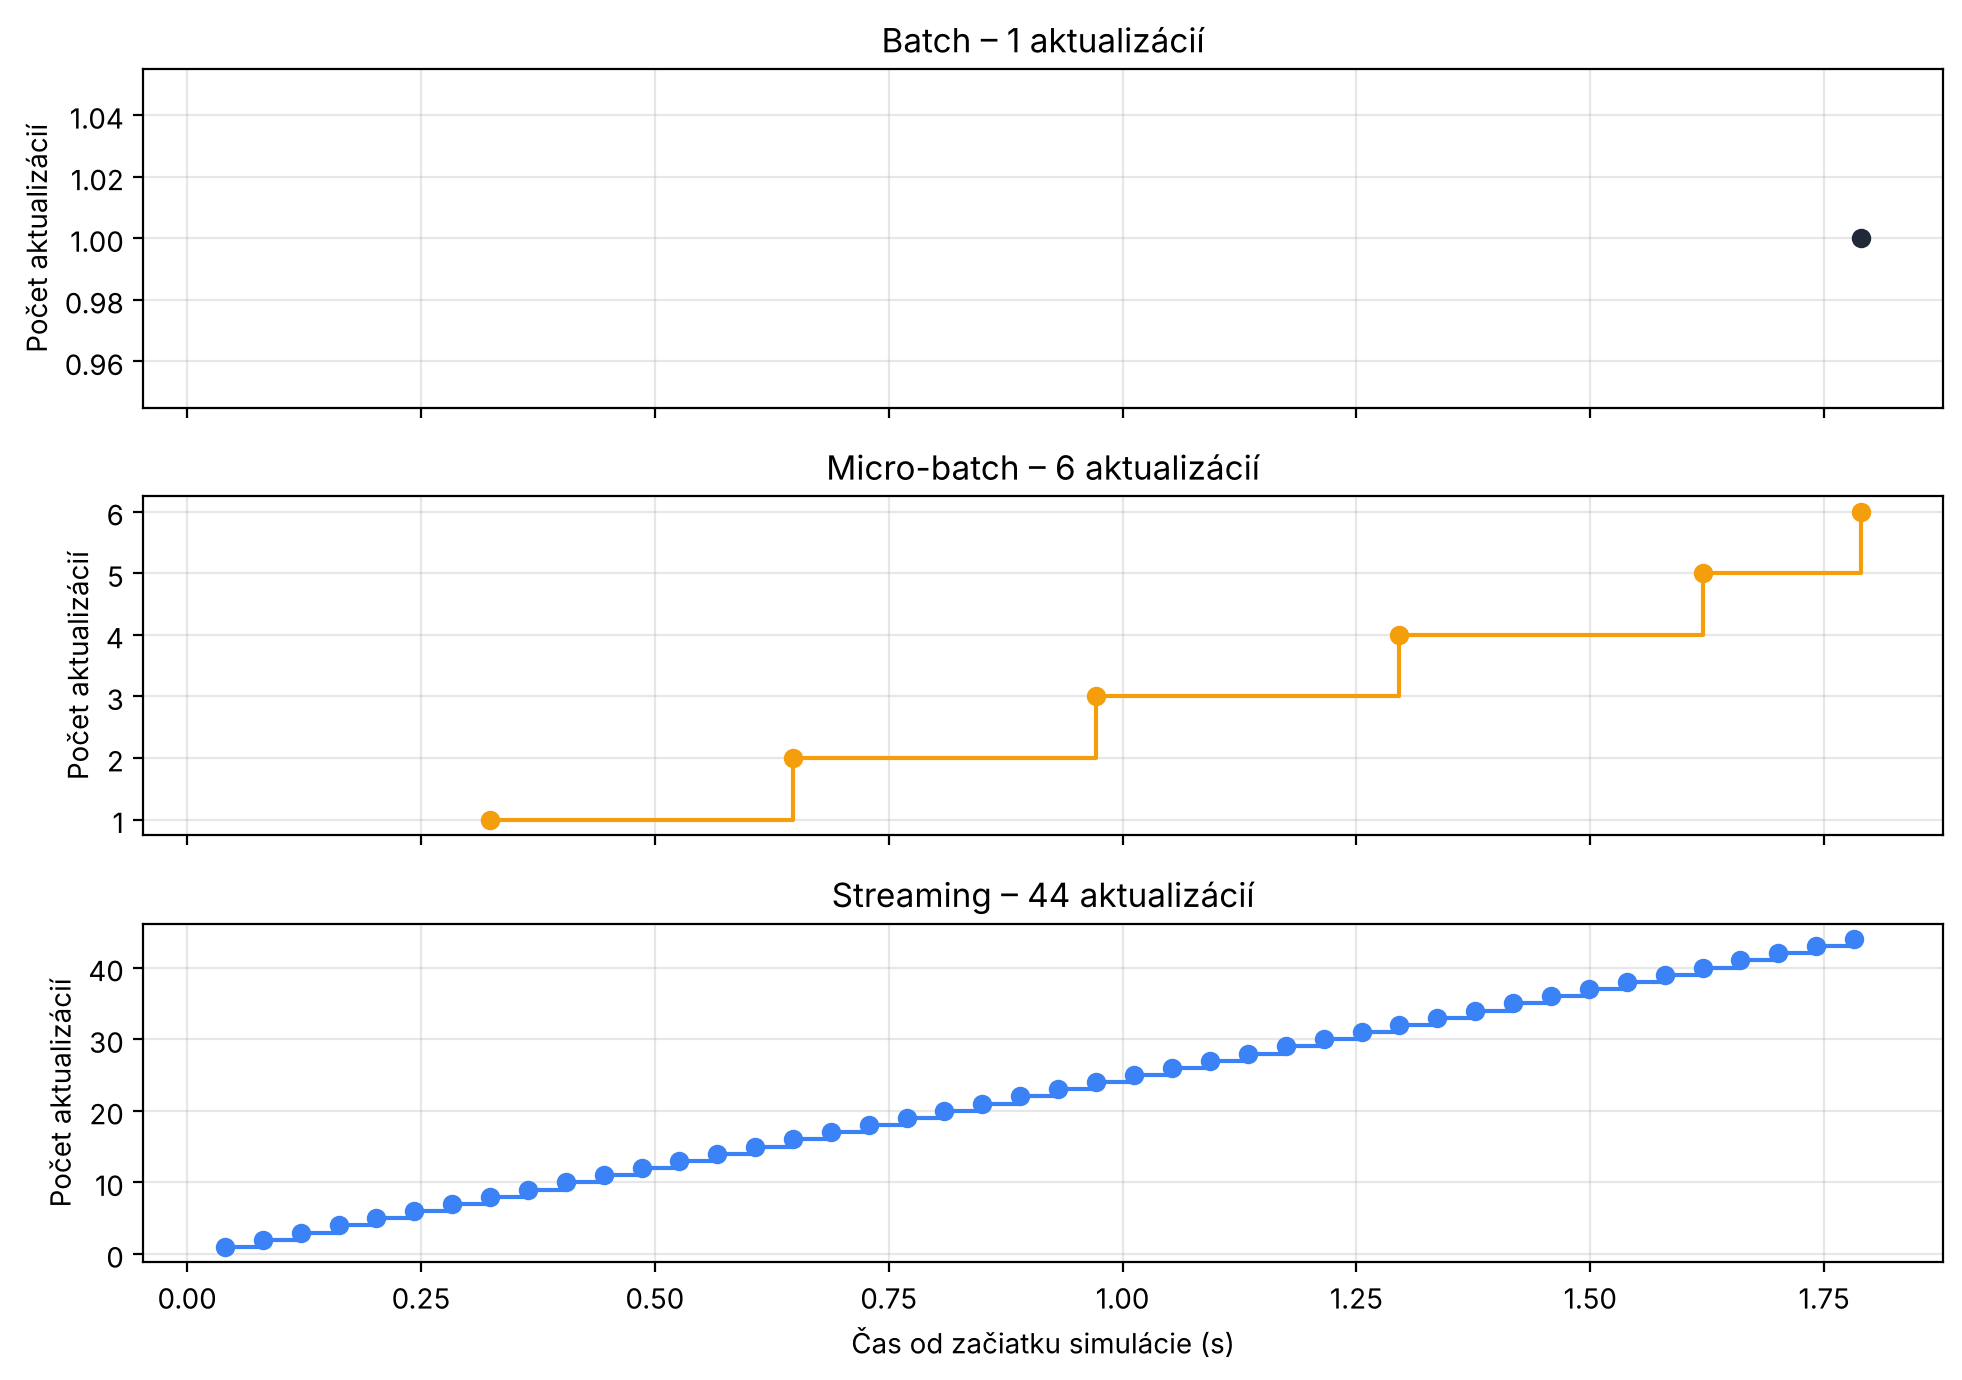

,Prístup,Čas prvého výsledku (s),Počet aktualizácií,Výsledok (%)
0,Batch,1.789,1,22.727
1,Micro-batch,0.324,6,22.727
2,Streaming,0.041,44,22.727


In [10]:
approaches = [
    ("Batch", batch_log, "#1f2937"),
    ("Micro-batch", mb_log, "#f59e0b"),
    ("Streaming", stream_log, "#3b82f6"),
]

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)   # os Y nezdieľame

for ax, (name, log, color) in zip(axes, approaches):
    times = [t for t, _, _ in log]
    ax.step(times, range(1, len(times) + 1), where="post", marker="o", color=color)
    ax.set_title(f"{name} – {len(times)} aktualizácií")
    ax.set_ylabel("Počet aktualizácií")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Čas od začiatku simulácie (s)")
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "Prístup": [name for name, _, _ in approaches],
    "Čas prvého výsledku (s)": [log[0][0] for _, log, _ in approaches],
    "Počet aktualizácií": [len(log) for _, log, _ in approaches],
    "Výsledok (%)": [log[-1][2] for _, log, _ in approaches],
}).round(3)

display(summary)

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">
  📘 Kontrola Git repozitára po 8. týždni
</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Po dokončení všetkých úloh z 8. týždňa skontrolujte, či máte vo svojom Git
  repozitári vytvorenú samostatnú vetvu
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  a či sa v nej nachádza vypracovaný notebook vytvorený počas cvičenia.
</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Obsah vetvy
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  by mal mať približne nasledujúcu štruktúru:
</p>
<pre style="background: #f9fafb; color: #111827; padding: 14px; border-radius: 7px; overflow: auto; font-size: 13px; line-height: 1.7; font-family: ui-monospace, SFMono-Regular, Menlo, monospace;">week-08
│
├── ratings.csv
├── orders.csv
│
├── batch_streaming.ipynb
└── batch_streaming_orders.ipynb
</pre>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #eab308; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">
  ⚠️ <strong>Kontrola GitHubu:</strong> Skontrolujte, či sa všetky uvedené súbory
  nachádzajú aj vo vzdialenom repozitári na GitHube. Ak ich vidíte iba lokálne
  vo VS Code, zmeny ešte neboli úspešne odoslané pomocou
  <strong>commit</strong> a <strong>push</strong>.
</div>